# GeoQA showcase: is Natural Earth's Africa country layer ready to publish as GeoJSON?

Data: Natural Earth 1:110m admin-0 countries (public domain), Africa only, in `data/africa_countries_ne110m.geojson` (EPSG:4326, lon/lat). Run this notebook from the `showcase/` folder.

In [1]:
import io
import sys
from pathlib import Path

from IPython.display import Image, display

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # use the repository checkout
import geoqa
from geoqa.geometry import GeometryChecker, TopologyChecker

gdf = gpd.read_file('data/africa_countries_ne110m.geojson')
print(len(gdf), 'features, CRS', gdf.crs)
gdf.drop(columns='geometry').head()

mkdir -p failed for path /home/agent/.cache/matplotlib: [Errno 13] Permission denied: '/home/agent/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-9_x8z_5d because there was an issue with the default path (/home/agent/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


51 features, CRS EPSG:4326


,name,iso_a3,pop_est
0,Tanzania,TZA,58005463.0
1,W. Sahara,ESH,603253.0
2,Dem. Rep. Congo,COD,86790567.0
3,Somalia,SOM,10192317.3
4,Kenya,KEN,52573973.0


## Profile and run the checks

In [2]:
prof = geoqa.profile(gdf, name='Africa countries')
geo = GeometryChecker(gdf).check_all()
topo = TopologyChecker(gdf).check_all()
pd.Series({
    'quality score': prof.quality_score,
    'features': geo['total_features'],
    'invalid geometries': geo['invalid_count'],
    'duplicates': geo['duplicate_count'],
    'overlapping pairs': topo['self_overlap_count'],
    'slivers': topo['sliver_count'],
    'clockwise exterior rings': topo['bad_ring_count'],
    'features with > 8 decimals': topo['excessive_precision_count'],
}, name='result', dtype=object).to_frame()

,result
quality score,100.0
features,51
invalid geometries,0
duplicates,0
overlapping pairs,0
slivers,0
clockwise exterior rings,51
features with > 8 decimals,51


## Areas in an equal-area CRS

Areas are computed in EPSG:6933 (metres), never in degrees.

In [3]:
gdf['area_km2'] = (gdf.to_crs('EPSG:6933').area / 1e6).round(0).astype(int)
gdf[['name', 'iso_a3', 'area_km2']].sort_values('area_km2', ascending=False).head(6)

,name,iso_a3,area_km2
2,Dem. Rep. Congo,COD,2323413
40,Algeria,DZA,2318480
5,Sudan,SDN,1849844
44,Libya,LBY,1634948
6,Chad,TCD,1270364
35,Angola,AGO,1245058


## Map

Egypt is outlined in red. The published `map.geojson` is the same data with exterior rings rewound counter-clockwise (RFC 7946); see `make_showcase.py`.

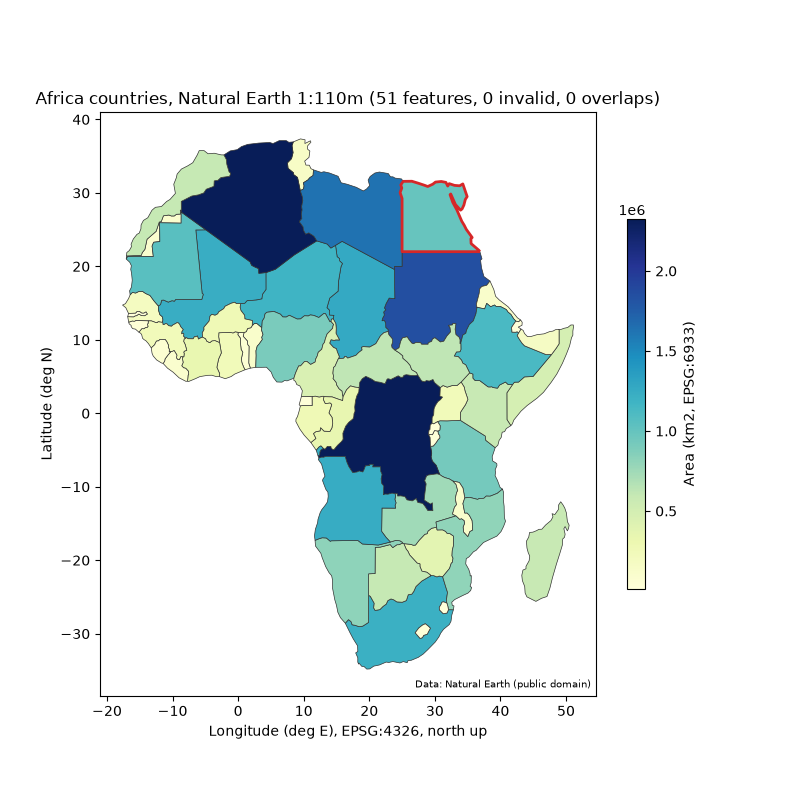

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
gdf.plot(column='area_km2', cmap='YlGnBu', edgecolor='#333', linewidth=0.5, ax=ax,
         legend=True, legend_kwds={'label': 'Area (km2, EPSG:6933)', 'shrink': 0.6})
gdf[gdf.iso_a3 == 'EGY'].boundary.plot(ax=ax, color='#d62728', linewidth=2)
ax.set_title('Africa countries, Natural Earth 1:110m (51 features, 0 invalid, 0 overlaps)')
ax.set_xlabel('Longitude (deg E), EPSG:4326, north up')
ax.set_ylabel('Latitude (deg N)')
ax.text(0.99, 0.01, 'Data: Natural Earth (public domain)', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=7)
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=100)
plt.close(fig)
display(Image(data=buf.getvalue()))